# MuJoCo［多关节接触仿真器］多步调用：保留控制周期

目标：比较逐步调用和 `mj_step(..., nstep=...)`。同一场景、初态、控制序列、步长和总物理步数，每20个物理步更新一次控制，两种实现都在每个控制边界记录状态。

这里优化解释器与原生函数之间的调用次数，使用处理器物理仿真；04的设备批量物理与原生条件图单独讲解。模型直接写在本篇，无需下载资产。

## 准备接触场景与固定控制序列

**本次原生设备实测：7.74679 → 6.92281 毫秒，1.119倍；计时单位为4000物理步、200次控制更新。正确性检查通过。**


In [1]:
from pathlib import Path
import json, hashlib, platform, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the course root from a source or exported notebook directory.
COURSE = next(p for p in [Path.cwd(), *Path.cwd().parents]
              if (p / "reproducibility/task-catalog.json").is_file())
EVIDENCE = COURSE / "notebooks/results/acceleration"
plt.rcParams.update({"figure.figsize": (8, 3.5), "font.size": 11})
print({"python": platform.python_version(), "evidence": str(EVIDENCE)})

import mujoco
XML = """<mujoco><option timestep="0.002" gravity="0 0 -9.81"/>
<worldbody><geom type="plane" size="2 2 .1"/>
<body pos="0 0 .4"><joint name="lift" type="slide" axis="0 0 1" damping=".2"/>
<geom type="sphere" size=".06" mass=".2"/></body></worldbody>
<actuator><motor joint="lift" gear="1"/></actuator></mujoco>"""
model = mujoco.MjModel.from_xml_string(XML)
controls = np.sin(np.linspace(0, 4*np.pi, 200)) * 3.0
SUBSTEPS = 20
print({"mujoco": mujoco.__version__, "processor_physics": True,
       "physical_steps": len(controls)*SUBSTEPS,
       "control_period_s": SUBSTEPS*model.opt.timestep})

print(json.loads((EVIDENCE / "amd-device-20261028-v1/device.json").read_text()))


{'python': '3.10.19', 'evidence': '/dev/shm/amd-acceleration-20261028-v1/course/notebooks/results/acceleration'}
{'mujoco': '3.10.0', 'processor_physics': True, 'physical_steps': 4000, 'control_period_s': 0.04}
{'hostname': 'aup-NucBox-EVO-X2', 'python': '3.10.19 (main, Oct 21 2025, 16:43:05) [GCC 11.2.0]', 'torch': '2.11.0+rocm7.13.0a20260425', 'hip': '7.13.26162', 'gpu': 'Radeon 8060S Graphics', 'remote_reported_time': '2026-10-29T03:40:02.777923+08:00', 'work_mount': '/dev/shm', 'work_free_bytes': 18131025920, 'scope': 'shared AMD device; other services left running; no training or robot task evaluation'}


## 把同一控制保持区间合并进原生调用
每个控制区间创建相同状态快照，计时包含相同的数据创建与记录成本。控制更新仍留在外层，禁止把需要每步重算的策略跨步跳过。

In [2]:
def rollout(batched):
    data = mujoco.MjData(model)
    states, contacts = [], []
    for action in controls:
        data.ctrl[0] = action
        if batched:
            mujoco.mj_step(model, data, nstep=SUBSTEPS)
        else:
            for _ in range(SUBSTEPS):
                mujoco.mj_step(model, data)
        states.append(np.r_[data.qpos.copy(), data.qvel.copy(), data.time])
        contacts.append(data.ncon)
    return np.asarray(states), np.asarray(contacts)

reference, contacts = rollout(False)
candidate, candidate_contacts = rollout(True)
assert np.isfinite(reference).all() and np.isfinite(candidate).all()
np.testing.assert_allclose(reference, candidate, rtol=0, atol=1e-12)
np.testing.assert_array_equal(contacts, candidate_contacts)
samples = {"Python step loop": [], "Native nstep": []}
for repeat in range(7):
    for label, batched in ([("Python step loop", False), ("Native nstep", True)] if repeat % 2 == 0
                           else [("Native nstep", True), ("Python step loop", False)]):
        start = time.perf_counter(); rollout(batched)
        samples[label].append((time.perf_counter()-start)*1000)
medians = {k: float(np.median(v)) for k,v in samples.items()}
display({"rollout_median_ms": medians, "raw_round_ms": samples,
         "speed_ratio": medians["Python step loop"]/medians["Native nstep"],
         "max_abs_state_error": float(np.max(np.abs(reference-candidate))),
         "control_boundary_contact_samples": int(np.count_nonzero(contacts)),
         "scope": "4000 physics steps, 200 unchanged control updates, 7 timing rounds"})


{'rollout_median_ms': {'Python step loop': 7.746794959530234,
  'Native nstep': 6.92281499505043},
 'raw_round_ms': {'Python step loop': [7.841745973564684,
   7.5384549563750625,
   8.121464983560145,
   7.624975056387484,
   7.678435067646205,
   7.746794959530234,
   7.757195038720965],
  'Native nstep': [7.524924003519118,
   6.8311350187286735,
   6.852325052022934,
   6.791683961637318,
   6.92281499505043,
   6.947423913516104,
   6.9778249599039555]},
 'speed_ratio': 1.1190238313560192,
 'max_abs_state_error': 0.0,
 'control_boundary_contact_samples': 87,
 'scope': '4000 physics steps, 200 unchanged control updates, 7 timing rounds'}

## 查看轨迹与耗时

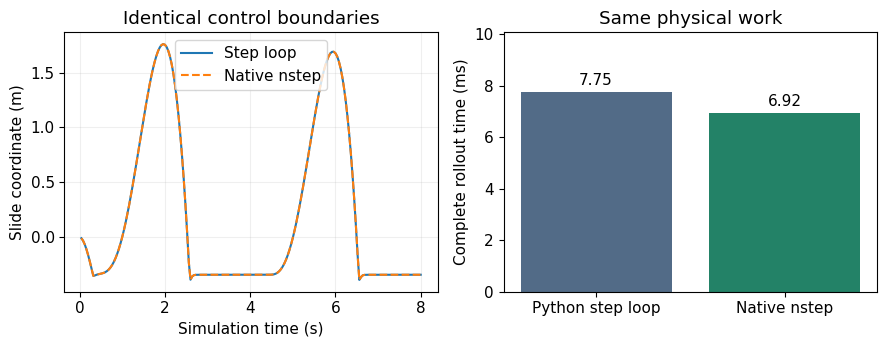

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].plot(reference[:,-1], reference[:,0], label="Step loop")
axes[0].plot(candidate[:,-1], candidate[:,0], "--", label="Native nstep")
axes[0].set(xlabel="Simulation time (s)", ylabel="Slide coordinate (m)", title="Identical control boundaries")
axes[0].legend(); axes[0].grid(alpha=.2)
axes[1].bar(medians.keys(), medians.values(), color=["#526b87", "#238267"])
axes[1].bar_label(axes[1].containers[0], fmt="%.2f", padding=3)
axes[1].set(ylabel="Complete rollout time (ms)", title="Same physical work", ylim=(0,max(medians.values())*1.3))
fig.tight_layout(); plt.show()


## 练习
把 `SUBSTEPS` 改为5或10后，同时重跑两种实现并检查全部控制边界；本练习的每个设置有各自控制频率。若要比较同一个机器人任务，先固定其原始控制周期，再选择等价的调用组织方式。原生多步调用期间需要逐步更新的控制，必须通过原生回调或继续逐步执行。